In [1]:
import pandas as pd
import plotly.graph_objects as go
import plotly.express as px
from IPython.display import Image, display
import os
import psycopg
from dotenv import load_dotenv
from datetime import datetime
import warnings
warnings.filterwarnings("ignore")

load_dotenv()

# Connect to PostgreSQL using environment variables
conn = psycopg.connect(
    host=os.getenv("PGHOST"),
    port=os.getenv("PGPORT"),
    dbname=os.getenv("PGDATABASE"),
    user=os.getenv("PGUSER"),
    password=os.getenv("PGPASSWORD"),
)
schema_name = os.getenv('PGSCHEMA')

In [2]:
COLORS = {
    "Beyrouth": {
        "persons": {
            "arrivals": "#A9D3F0",
            "departures": "#5DA5DA",
            "money": "#85BCE6",
        },
        "cargo": {
            "arrivals": "#80B3D9",
            "departures": "#377EB8",
            "money": "#5B91B8"
        },
    },
    "Marseille": {
        "persons": {
            "arrivals": "#B8E0C5",
            "departures": "#70B77E",
            "money": "#96CEA5",
        },
        "cargo": {
            "arrivals": "#8AC69A",
            "departures": "#3F8F55",
            "money": "#4F9464"
        },
    },
    "Alexandrie": {
        "persons": {
            "arrivals": "#F7D6A5",
            "departures": "#E9A857",
            "money": "#F0C17E",
        },
        "cargo": {
            "arrivals": "#E8B873",
            "departures": "#C98632",
            "money": "#C28A3E"
        },
    },
    "Haifa": {
        "persons": {
            "arrivals": "#E8C6E8",
            "departures": "#C58BC5",
            "money": "#D7A9D7",
        },
        "cargo": {
            "arrivals": "#CB9ACB",
            "departures": "#A15AA1",
            "money": "#995999"
        },
    },
}
COLORS_CLASSES = ["#E6A3A3", "#A6A0D8", "#D4D89A", "#8FD3CF"]

In [3]:
def load_table_data(conn: psycopg.Connection, table_name: str) -> pd.DataFrame:
    """Load all rows from a SQLite table into a pandas DataFrame."""

    # Build the SELECT query.
    query = f"SELECT * FROM {schema_name}.{table_name}"

    # Execute the query and let pandas build the DataFrame.
    return pd.read_sql_query(query, conn)


def add_year_month_columns(df: pd.DataFrame, date_column: str, prefix: str = "", drop_col: bool = True) -> pd.DataFrame:
    """Extract the year and month from an ISO-formatted date column."""

    # Convert the column to datetime objects.
    # errors="coerce" turns invalid dates into NaT instead of raising an error.
    dates = pd.to_datetime(df[date_column], errors="coerce")

    # Add the year as an integer column.
    df[f"{prefix}year"] = dates.dt.year

    # Add the month as a two-digit string ("05", not "5").
    df[f"{prefix}month"] = dates.dt.strftime("%m")

    # Remove the given column and return everything
    if drop_col: df.drop(columns=[date_column], inplace=True)

    # Set new columns types to int
    df[f"{prefix}year"] = df[f"{prefix}year"].astype(pd.Int64Dtype())
    df[f"{prefix}month"] = df[f"{prefix}month"].astype(pd.Int64Dtype())

    return df


def convert_to_integer(df: pd.DataFrame, columns: list[str]) -> pd.DataFrame:
    """For each given column, convert columns containing incorrectly formatted integers to integers."""

    for column in columns:
        # Convert values to strings so we can safely manipulate separators.
        # values = df[column].astype("string")

        # # Remove commas and dots used as thousands separators.
        # values = values.str.replace(",", "", regex=False)
        # values = values.str.replace(".", "", regex=False)

        # Convert the cleaned values to integers.
        # Invalid values are replaced with NaN instead of raising an error.
        df[column] = pd.to_numeric(df[column], errors="coerce").astype(pd.Int64Dtype())

    return df


def get_details_of_geo_place(geo_place_name: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Get person and cargo arrival/departure details for a geographical place."""

    # Get the primary key of the requested geographical place.
    pk_geo_place = geo_place[geo_place['name'].map(lambda x: x.strip() if isinstance(x, str) else False) == geo_place_name]['pk_geogr_place'].iloc[0]

    # Get all steps associated with the geographical place.
    selected_steps: pd.DataFrame = step[step["fk_geo_place"] == pk_geo_place]

    # Join steps with person-related and cargo-related data.
    geo_place_steps_persons = selected_steps.merge(step_persons, how='left', left_on="pk_step", right_on="fk_step")
    geo_place_steps_cargo = selected_steps.merge(step_cargo, how='left', left_on="pk_step", right_on="fk_step_cargo")

    # Select arrival and departure information.
    df_arrival_persons = geo_place_steps_persons[['fk_step', 'arrival_date_iso', 'd_1', 'd_2', 'd_3', 'd_4']]
    df_arrival_persons['total_persons'] = df_arrival_persons[['d_1', 'd_2', 'd_3', 'd_4']].sum(axis=1)
    df_departure_persons = geo_place_steps_persons[['fk_step', 'departure_date_iso', 'e_1', 'e_2', 'e_3', 'e_4', 'income']]
    df_departure_persons['total_persons'] = df_departure_persons[['e_1', 'e_2', 'e_3', 'e_4']].sum(axis=1)
    df_arrival_cargo = geo_place_steps_cargo[['fk_step_cargo', 'dis_weight_in_tons']]
    df_departure_cargo = geo_place_steps_cargo[['fk_step_cargo', 'emb_weight_in_tons', 'income']]

    # Change name of concurrenet columns so that there is no overlap when merging
    df_departure_persons.rename(columns={'income':'income_passenger'}, inplace=True)
    df_departure_cargo.rename(columns={'income':'income_cargo'}, inplace=True)

    # Merge both persons and cargo into one single arrival and departure DataFrame
    df_arrival = pd.merge(df_arrival_persons, df_arrival_cargo, left_on='fk_step', right_on='fk_step_cargo', how="right")
    df_departure = pd.merge(df_departure_persons, df_departure_cargo, left_on='fk_step', right_on='fk_step_cargo', how="right")

    # Extract year and month from the arrival and departure dates.
    df_arrival = add_year_month_columns(df_arrival, 'arrival_date_iso', '')
    df_departure = add_year_month_columns(df_departure, 'departure_date_iso', '')

    # Remove unecessary columns
    df_arrival.drop(columns=['fk_step_cargo'], inplace=True)
    df_departure.drop(columns=['fk_step_cargo'], inplace=True)

    return df_arrival, df_departure


def get_globals_steps() -> tuple[pd.DataFrame, pd.DataFrame]:
    """Format, ready for analysis all voyage steps."""

    # Join steps with person-related and cargo-related data.
    step_step_persons = step.merge(step_persons, how='left', left_on="pk_step", right_on="fk_step")
    step_step_cargo = step.merge(step_cargo, how='left', left_on="pk_step", right_on="fk_step_cargo")

    # Select arrival and departure information.
    df_arrival_persons = step_step_persons[['fk_step', 'arrival_date_iso', 'd_1', 'd_2', 'd_3', 'd_4']]
    df_arrival_persons['total_persons'] = df_arrival_persons[['d_1', 'd_2', 'd_3', 'd_4']].sum(axis=1)
    df_departure_persons = step_step_persons[['fk_step', 'departure_date_iso', 'e_1', 'e_2', 'e_3', 'e_4', 'income']]
    df_departure_persons['total_persons'] = df_departure_persons[['e_1', 'e_2', 'e_3', 'e_4']].sum(axis=1)
    df_arrival_cargo = step_step_cargo[['fk_step_cargo', 'dis_weight_in_tons']]
    df_departure_cargo = step_step_cargo[['fk_step_cargo', 'emb_weight_in_tons', 'income']]

    # Change name of concurrenet columns so that there is no overlap when merging
    df_departure_persons.rename(columns={'income':'income_passenger'}, inplace=True)
    df_departure_cargo.rename(columns={'income':'income_cargo'}, inplace=True)

    # Merge both persons and cargo into one single arrival and departure DataFrame
    df_arrival = pd.merge(df_arrival_persons, df_arrival_cargo, left_on='fk_step', right_on='fk_step_cargo', how="right")
    df_departure = pd.merge(df_departure_persons, df_departure_cargo, left_on='fk_step', right_on='fk_step_cargo', how="right")

    # Extract year and month from the arrival and departure dates.
    df_arrival = add_year_month_columns(df_arrival, 'arrival_date_iso', '')
    df_departure = add_year_month_columns(df_departure, 'departure_date_iso', '')

    # Remove unecessary columns
    df_arrival.drop(columns=['fk_step_cargo'], inplace=True)
    df_departure.drop(columns=['fk_step_cargo'], inplace=True)
    
    return df_arrival, df_departure


def get_analysis_df(arrivals: pd.DataFrame, departures: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """From a given couple of DataFrames, prepare the same couple, but ready for analysis."""

    # Group everything by the year, and make the sum of columns
    arrivals_years = arrivals.groupby('year').sum()
    departure_years = departures.groupby('year').sum()

    # Reset indexes: put years back in place (as normal columns)
    arrivals_years = arrivals_years.reset_index()
    departure_years = departure_years.reset_index()

    return arrivals_years, departure_years


def get_totals(arrivals: pd.DataFrame, departures: pd.DataFrame) -> dict:
    """Compute totals of given DataFrames."""

    return {
        "arrivals_person": arrivals['total_persons'].sum(),
        "arrivals_cargo": arrivals['dis_weight_in_tons'].sum(),
        "departure_person": departures['total_persons'].sum(),
        "departure_cargo": departures['emb_weight_in_tons'].sum()
    }


def get_group_by_months(arrivals: pd.DataFrame, departures: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Group by column "month" the 2 given DataFrames, and return them correctly formated."""

    arrivals_months = arrivals.groupby('month').mean().reset_index()
    departure_months = departures.groupby('month').mean().reset_index() 

    return arrivals_months, departure_months

In [4]:
# Load all needed table from the Database
voyages = load_table_data(conn, 'voyage')
geo_place = load_table_data(conn, 'geogr_place')
step = load_table_data(conn, 'step')
step = step[step['pk_step'] != pd.NA]
step_persons = load_table_data(conn, 'step_persons')
step_cargo = load_table_data(conn, 'step_cargo')

# Because columns are wrongly formated: integer are not really integers in the listed columns: 
# sometimes have a comma or dot mixing up.
step_persons = convert_to_integer(step_persons, ['d_1', 'd_2', 'd_3', 'd_4', 'e_1', 'e_2', 'e_3', 'e_4', 'income'])
step_cargo = convert_to_integer(step_cargo, ['dis_weight_in_tons', 'emb_weight_in_tons', 'income'])

In [5]:
# Manual making pouring year 1929 into 1930, they are only some step that makes charts unclear

def revise_date(date: str) -> str:
    if not pd.isna(date) and date.startswith('1929-'):
        return date.replace('1929-', '1930-')
    else: return date

step['arrival_date_iso'] = [revise_date(x) for x in step['arrival_date_iso']]
step['departure_date_iso'] = [revise_date(x) for x in step['departure_date_iso']]

In [6]:
# Filter out some years: they are not complete
white_list_year = [1926, 1928, 1930, 1932, 1934, 1936]
white_list_ship = [1]

def is_valid_year(date: str) -> bool:
    if pd.isna(date): return False
    if date == '': return False
    try: return datetime.fromisoformat(str(date)).year in white_list_year
    except ValueError: return False

def is_valid_ship(ship: int) -> bool:
    return ship in white_list_ship

voyages = voyages[[is_valid_year(d) for d in voyages['arrival_date_iso']]]
voyages = voyages[[is_valid_ship(i) for i in voyages['fk_ship']]]
valid_voyages = set(voyages['pk_voyage'])
step = step[[fk in valid_voyages for fk in step['fk_voyage']]]
valid_steps = set(step['pk_step'])
step_cargo = step_cargo[[fk in valid_steps for fk in step_cargo['fk_step_cargo']]]
step_persons = step_persons[[fk in valid_steps for fk in step_persons['fk_step']]]

# Comment les flux de passagers et de marchandises à Beyrouth (par le Mariette Pacha) ont-ils évolués entre 1926 et 1939, et quel rôle avait Beyrouth dans le réseau maritime des Messageries Maritimes ?

In [7]:
# Data of interest (used mutliple times accross the analysis)

# Global data, not filtered by city
global_arrivals, global_departures = get_globals_steps()
begin_year = min(global_arrivals['year'].min(), global_departures['year'].min())
end_year = max(global_arrivals['year'].max(), global_departures['year'].max())

# Beirut
beirut_arrivals, beirut_departures = get_details_of_geo_place('Beirut')
beirut_totals = get_totals(beirut_arrivals, beirut_departures)
beirut_arrivals_year, beirut_departure_year = get_analysis_df(beirut_arrivals, beirut_departures)

# Marseille
marseille_arrivals, marseille_departures = get_details_of_geo_place('Marseille')
marseille_totals = get_totals(marseille_arrivals, marseille_departures)
marseille_arrivals_year, marseille_departure_year = get_analysis_df(marseille_arrivals, marseille_departures)

# Alexandria
alexandria_arrivals, alexandria_departures = get_details_of_geo_place('Alexandria')
alexandria_totals = get_totals(alexandria_arrivals, alexandria_departures)
alexandria_arrivals_year, alexandria_departure_year = get_analysis_df(alexandria_arrivals, alexandria_departures)

# Haifa
haifa_arrivals, haifa_departures = get_details_of_geo_place('Haifa')
haifa_totals = get_totals(haifa_arrivals, haifa_departures)
haifa_arrivals_year, haifa_departure_year = get_analysis_df(haifa_arrivals, haifa_departures)

# Get total arrivals and departure for persons and cargos
totals = get_totals(global_arrivals, global_departures)
print('Total arrivées personnes: ', totals['arrivals_person'])
print('Total départs personnes: ', totals['departure_person'])
print('Total arrivées cargo (tonnes): ', totals['arrivals_cargo'])
print('Total départs cargo (tonnes): ', totals['departure_cargo'])

Total arrivées personnes:  60732
Total départs personnes:  60026
Total arrivées cargo (tonnes):  99899
Total départs cargo (tonnes):  99401


## A. Les passagers et marchandises du Mariette Pacha débarquant et embarquant dans les ports de Beyrouth, Marseille, Alexandie, et Haifa

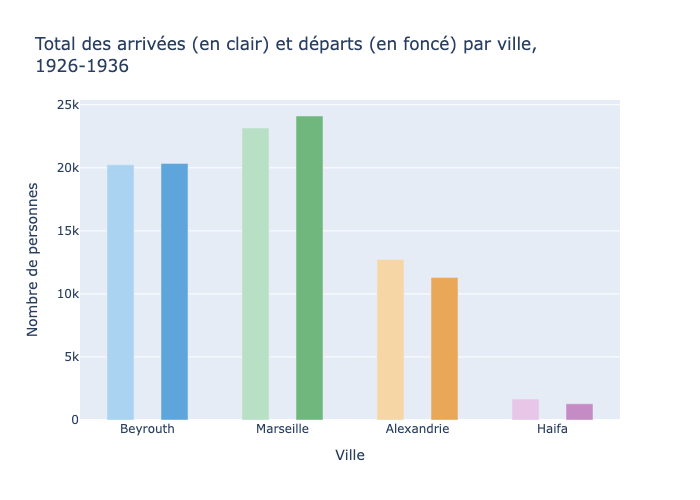

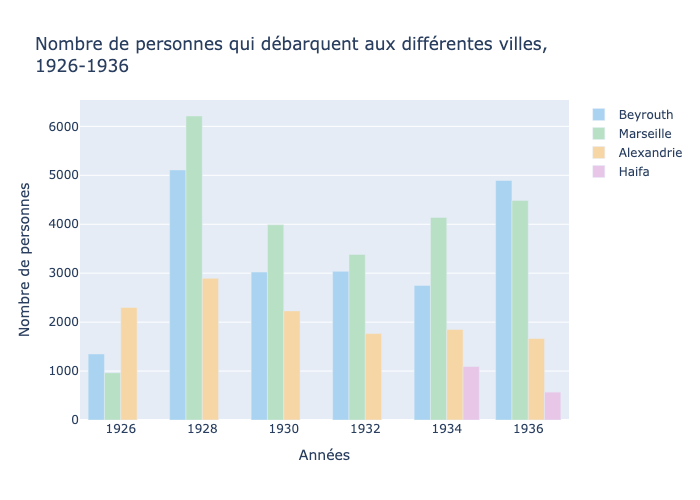

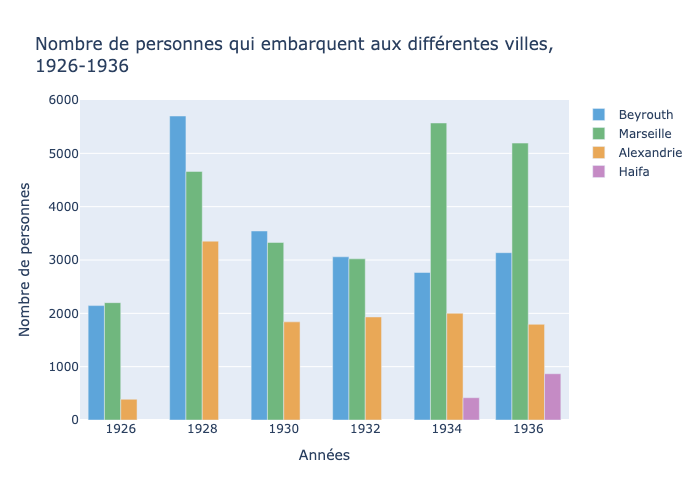

In [8]:
fig = go.Figure()
x = ["Beyrouth", "Marseille", "Alexandrie", "Haifa"]
key = "arrivals_person" # Just to shorten following line
colors=[COLORS['Beyrouth']['persons']['arrivals'], COLORS['Marseille']['persons']['arrivals'], COLORS['Alexandrie']['persons']['arrivals'], COLORS['Haifa']['persons']['arrivals']]
fig.add_trace(go.Bar(x=x, y=[beirut_totals[key], marseille_totals[key], alexandria_totals[key], haifa_totals[key]], name="Arrivées", width=0.2, marker_color=colors, showlegend=False))
key = "departure_person" # Just to shorten following line
colors=[COLORS['Beyrouth']['persons']['departures'], COLORS['Marseille']['persons']['departures'], COLORS['Alexandrie']['persons']['departures'], COLORS['Haifa']['persons']['departures']]
fig.add_trace(go.Bar(x=x, y=[beirut_totals["departure_person"], marseille_totals["departure_person"], alexandria_totals["departure_person"], haifa_totals["departure_person"]], name="Départs", width=0.2, marker_color=colors, showlegend=False))
fig.update_layout(title=f"Total des arrivées (en clair) et départs (en foncé) par ville,<br>{begin_year}-{end_year}", xaxis_title="Ville", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("total-arrivals-departures-city.png")
display(Image(filename="total-arrivals-departures-city.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["total_persons"], name="Beyrouth", marker_color=COLORS['Beyrouth']['persons']['arrivals']))
fig.add_trace(go.Bar(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["total_persons"], name="Marseille", marker_color=COLORS['Marseille']['persons']['arrivals']))
fig.add_trace(go.Bar(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["total_persons"], name="Alexandrie", marker_color=COLORS['Alexandrie']['persons']['arrivals']))
fig.add_trace(go.Bar(x=haifa_arrivals_year["year"], y=haifa_arrivals_year["total_persons"], name="Haifa", marker_color=COLORS['Haifa']['persons']['arrivals']))
fig.update_layout(title=f"Nombre de personnes qui débarquent aux différentes villes,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("persons-arrivals-city.png")
display(Image(filename="persons-arrivals-city.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["total_persons"], name="Beyrouth", marker_color=COLORS['Beyrouth']['persons']['departures']))
fig.add_trace(go.Bar(x=marseille_departure_year["year"], y=marseille_departure_year["total_persons"], name="Marseille", marker_color=COLORS['Marseille']['persons']['departures']))
fig.add_trace(go.Bar(x=alexandria_departure_year["year"], y=alexandria_departure_year["total_persons"], name="Alexandrie", marker_color=COLORS['Alexandrie']['persons']['departures']))
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["total_persons"], name="Haifa", marker_color=COLORS['Haifa']['persons']['departures']))
fig.update_layout(title=f"Nombre de personnes qui embarquent aux différentes villes,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("persons-departures-city.png")
display(Image(filename="persons-departures-city.png"))

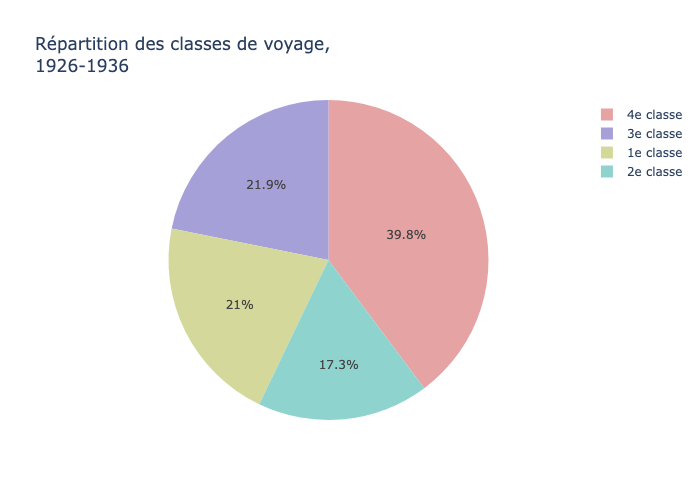

In [9]:
fig = px.pie(
    names=['1e classe', '2e classe', '3e classe', '4e classe'],
    values=[global_departures['e_1'].sum(), global_departures['e_2'].sum(), global_departures['e_3'].sum(), global_departures['e_4'].sum()],
    title=f"Répartition des classes de voyage,<br>{begin_year}-{end_year}",
    color_discrete_sequence=COLORS_CLASSES
)
fig.write_image("persons-classes.png")
display(Image(filename="persons-classes.png"))

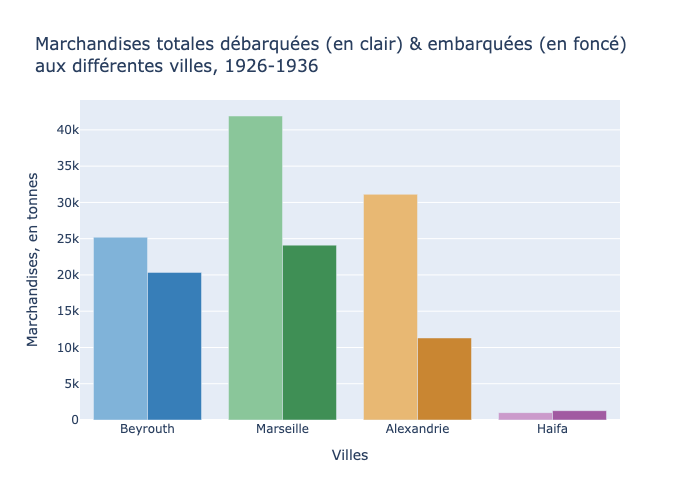

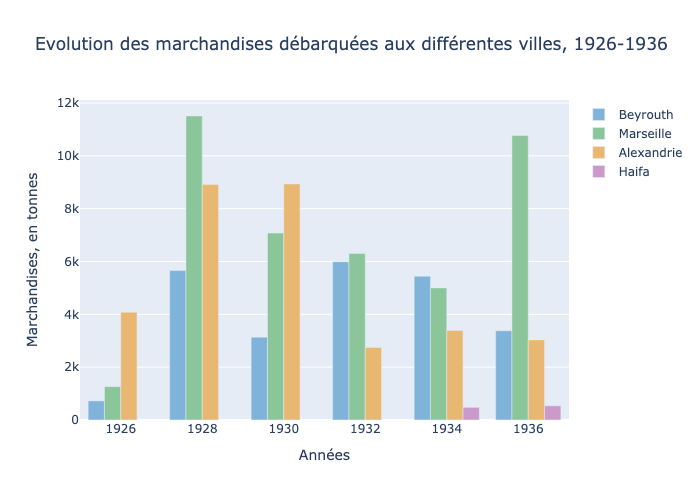

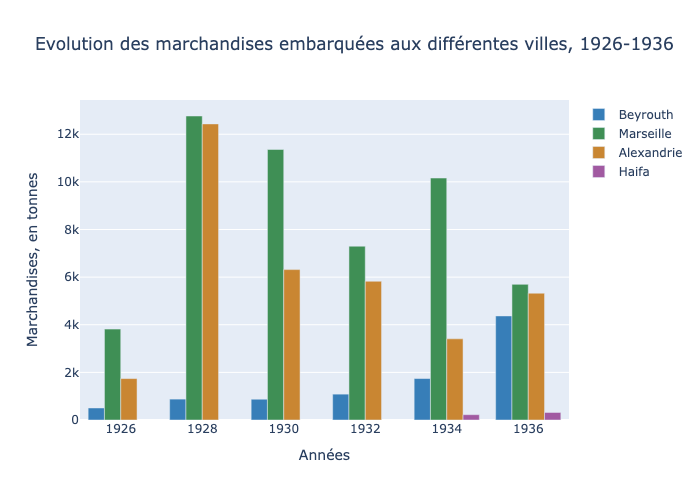

In [10]:
# Create the grouped bar chart
fig = go.Figure()
x = ["Beyrouth", "Marseille", "Alexandrie", "Haifa"]
key = "arrivals_cargo" # Just to shorten following line
colors=[COLORS['Beyrouth']['cargo']['arrivals'], COLORS['Marseille']['cargo']['arrivals'], COLORS['Alexandrie']['cargo']['arrivals'], COLORS['Haifa']['cargo']['arrivals']]
fig.add_trace(go.Bar(x=x, y=[beirut_totals[key], marseille_totals[key], alexandria_totals[key], haifa_totals[key]], name="Arrivées", marker_color=colors, showlegend=False))
key = "departure_cargo" # Just to shorten following line
colors=[COLORS['Beyrouth']['cargo']['departures'], COLORS['Marseille']['cargo']['departures'], COLORS['Alexandrie']['cargo']['departures'], COLORS['Haifa']['cargo']['departures']]
fig.add_trace(go.Bar(x=x, y=[beirut_totals["departure_person"], marseille_totals["departure_person"], alexandria_totals["departure_person"], haifa_totals["departure_person"]], name="Départs", marker_color=colors, showlegend=False))
fig.update_layout(title=f"Marchandises totales débarquées (en clair) & embarquées (en foncé)<br>aux différentes villes, {begin_year}-{end_year}", xaxis_title="Villes", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("cargo-city.png")
display(Image(filename="cargo-city.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["dis_weight_in_tons"], name="Beyrouth", marker_color=COLORS['Beyrouth']['cargo']['arrivals']))
fig.add_trace(go.Bar(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["dis_weight_in_tons"], name="Marseille", marker_color=COLORS['Marseille']['cargo']['arrivals']))
fig.add_trace(go.Bar(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["dis_weight_in_tons"], name="Alexandrie", marker_color=COLORS['Alexandrie']['cargo']['arrivals']))
fig.add_trace(go.Bar(x=haifa_arrivals_year["year"], y=haifa_arrivals_year["dis_weight_in_tons"], name="Haifa", marker_color=COLORS['Haifa']['cargo']['arrivals']))
fig.update_layout(title=f"Evolution des marchandises débarquées aux différentes villes, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("cargo-arrivals-city.png")
display(Image(filename="cargo-arrivals-city.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["emb_weight_in_tons"], name="Beyrouth", marker_color=COLORS['Beyrouth']['cargo']['departures']))
fig.add_trace(go.Bar(x=marseille_departure_year["year"], y=marseille_departure_year["emb_weight_in_tons"], name="Marseille", marker_color=COLORS['Marseille']['cargo']['departures']))
fig.add_trace(go.Bar(x=alexandria_departure_year["year"], y=alexandria_departure_year["emb_weight_in_tons"], name="Alexandrie", marker_color=COLORS['Alexandrie']['cargo']['departures']))
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["emb_weight_in_tons"], name="Haifa", marker_color=COLORS['Haifa']['cargo']['departures']))
fig.update_layout(title=f"Evolution des marchandises embarquées aux différentes villes, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("cargo-departure-city.png")
display(Image(filename="cargo-departure-city.png"))

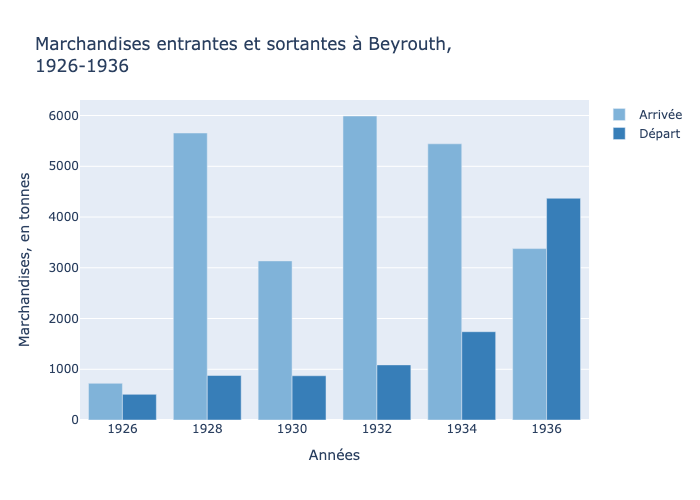

In [11]:
fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["dis_weight_in_tons"], name="Arrivée", marker_color=COLORS['Beyrouth']['cargo']['arrivals']))
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["emb_weight_in_tons"], name="Départ", marker_color=COLORS['Beyrouth']['cargo']['departures']))
fig.update_layout(title=f"Marchandises entrantes et sortantes à Beyrouth,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("beirut-cargo.png")
display(Image(filename="beirut-cargo.png"))

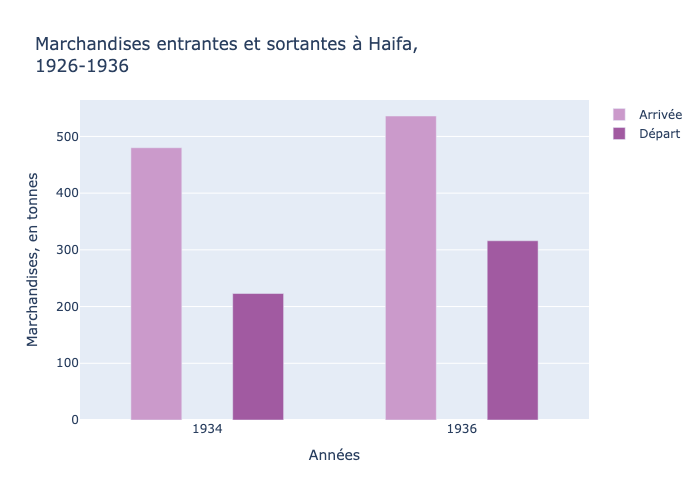

In [12]:
fig = go.Figure()
fig.add_trace(go.Bar(x=haifa_arrivals_year["year"], y=haifa_arrivals_year["dis_weight_in_tons"], name="Arrivée", marker_color=COLORS['Haifa']['cargo']['arrivals'], width=0.4))
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["emb_weight_in_tons"], name="Départ", marker_color=COLORS['Haifa']['cargo']['departures'], width=0.4))
fig.update_layout(title=f"Marchandises entrantes et sortantes à Haifa,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Marchandises, en tonnes", barmode="group")
fig.write_image("haifa-cargo.png")
display(Image(filename="haifa-cargo.png"))

## B. Evolution & comparaison du nombre de débarquants/embarquants pour différentes ville sur la période, pour le Mariette Pacha

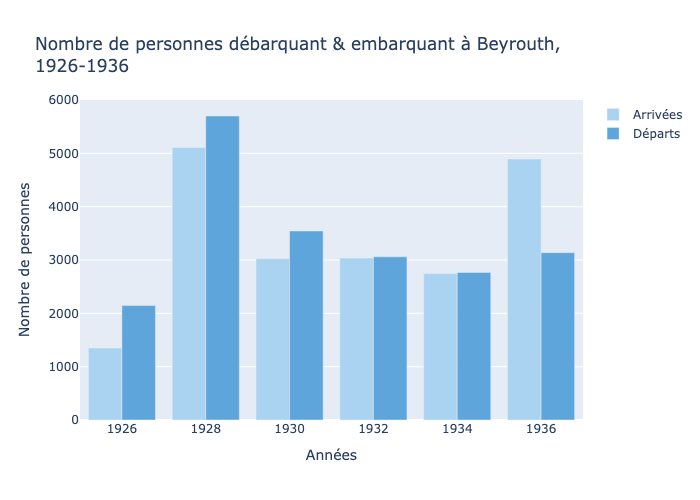

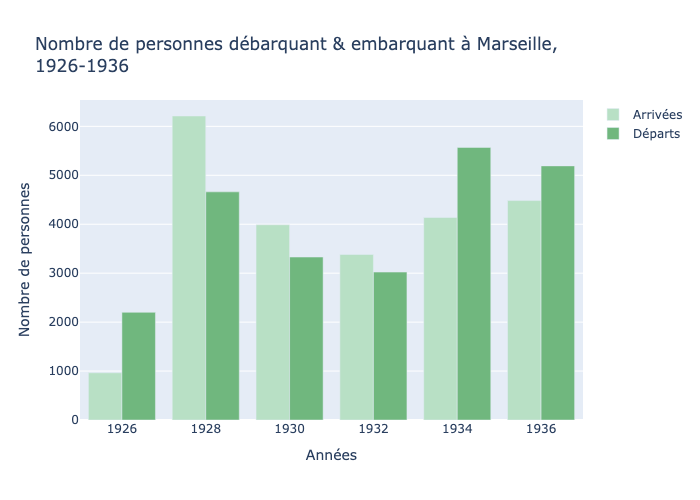

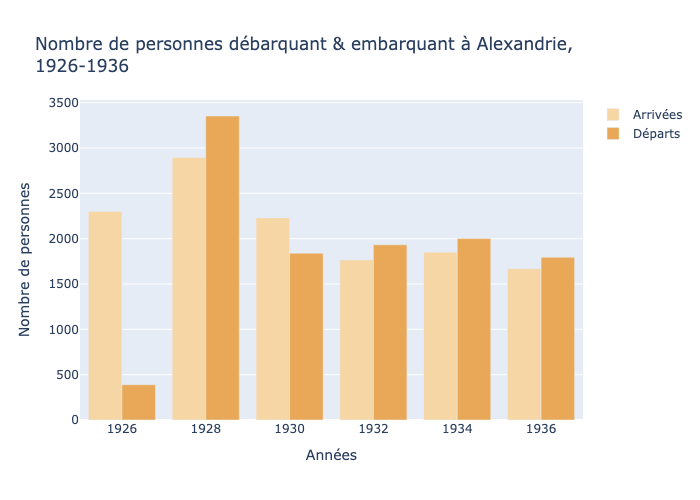

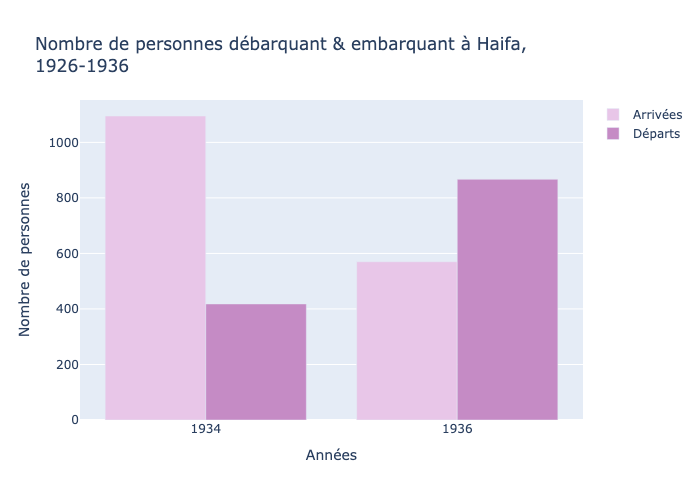

In [13]:
fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_arrivals_year["year"], y=beirut_arrivals_year["total_persons"], name="Arrivées", marker_color=COLORS['Beyrouth']['persons']['arrivals']))
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["total_persons"], name="Départs", marker_color=COLORS['Beyrouth']['persons']['departures']))
fig.update_layout(title=f"Nombre de personnes débarquant & embarquant à Beyrouth,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("beirut-persons.png")
display(Image(filename="beirut-persons.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=marseille_arrivals_year["year"], y=marseille_arrivals_year["total_persons"], name="Arrivées", marker_color=COLORS['Marseille']['persons']['arrivals']))
fig.add_trace(go.Bar(x=marseille_departure_year["year"], y=marseille_departure_year["total_persons"], name="Départs", marker_color=COLORS['Marseille']['persons']['departures']))
fig.update_layout(title=f"Nombre de personnes débarquant & embarquant à Marseille,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("marseille-persons.png")
display(Image(filename="marseille-persons.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=alexandria_arrivals_year["year"], y=alexandria_arrivals_year["total_persons"], name="Arrivées", marker_color=COLORS['Alexandrie']['persons']['arrivals']))
fig.add_trace(go.Bar(x=alexandria_departure_year["year"], y=alexandria_departure_year["total_persons"], name="Départs", marker_color=COLORS['Alexandrie']['persons']['departures']))
fig.update_layout(title=f"Nombre de personnes débarquant & embarquant à Alexandrie,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("alexandria-persons.png")
display(Image(filename="alexandria-persons.png"))

fig = go.Figure()
fig.add_trace(go.Bar(x=haifa_arrivals_year["year"], y=haifa_arrivals_year["total_persons"], name="Arrivées", marker_color=COLORS['Haifa']['persons']['arrivals']))
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["total_persons"], name="Départs", marker_color=COLORS['Haifa']['persons']['departures']))
fig.update_layout(title=f"Nombre de personnes débarquant & embarquant à Haifa,<br>{begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Nombre de personnes", barmode="group")
fig.write_image("haifa-persons.png")
display(Image(filename="haifa-persons.png"))

## C. Recettes du Mariette Pacha sur la période

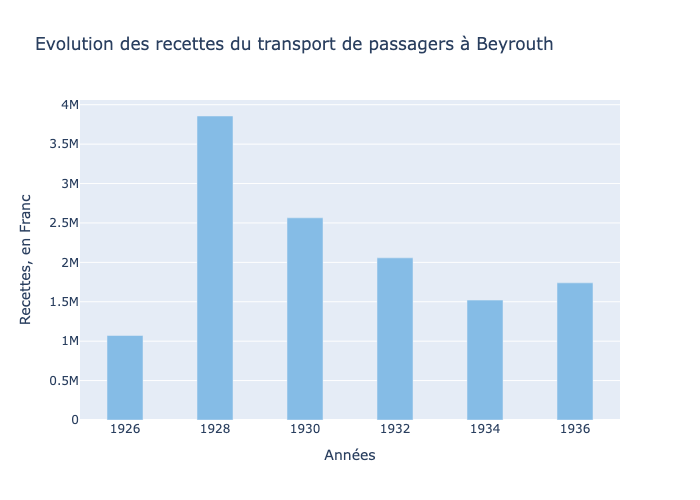

In [14]:
fig = px.bar(
    beirut_departure_year,
    x="year",
    y="income_passenger",
    title="Evolution des recettes du transport de passagers à Beyrouth",
    labels={
        "year": "Années",
        "income_passenger": "Recettes, en Franc",
    },
)
fig.update_traces(width=0.8, marker_color=COLORS['Beyrouth']['persons']['money'])
fig.write_image("beirut-persons-income.png")
display(Image(filename="beirut-persons-income.png"))

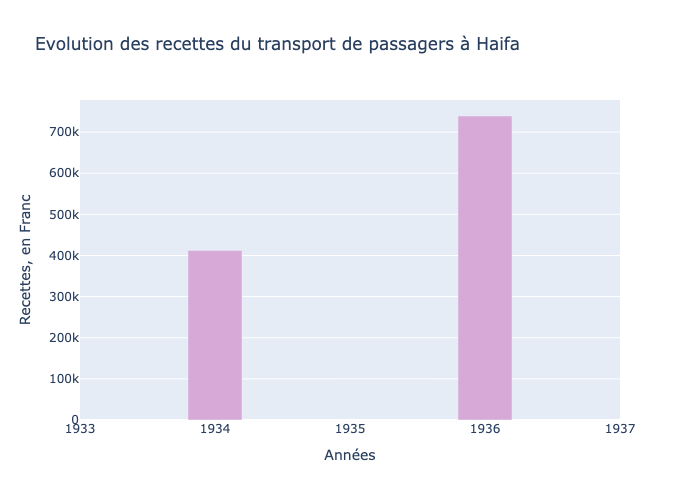

In [15]:
fig = px.bar(
    haifa_departure_year,
    x="year",
    y="income_passenger",
    title="Evolution des recettes du transport de passagers à Haifa",
    labels={
        "year": "Années",
        "income_passenger": "Recettes, en Franc",
    },
)
fig.update_traces(width=0.4, marker_color=COLORS['Haifa']['persons']['money'])
fig.write_image("haifa-persons-income.png")
display(Image(filename="haifa-persons-income.png"))

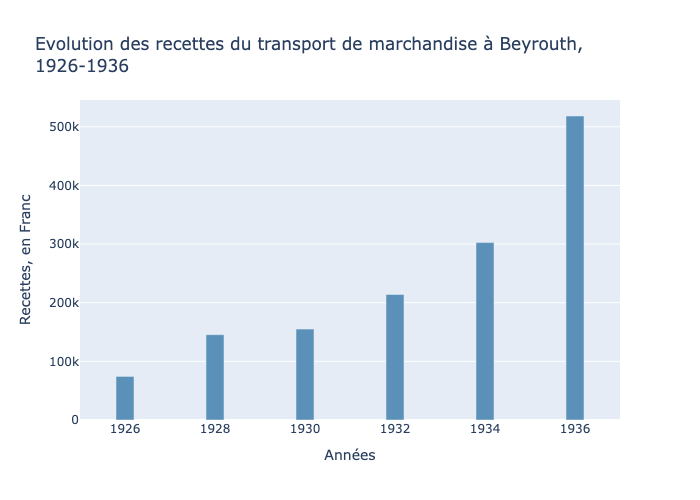

In [16]:
fig = px.bar(
    beirut_departure_year,
    x="year",
    y="income_cargo",
    title=f"Evolution des recettes du transport de marchandise à Beyrouth,<br>{begin_year}-{end_year}",
    labels={
        "year": "Années",
        "income_cargo": "Recettes, en Franc",
    }
)
fig.update_traces(width=0.4, marker_color=COLORS['Beyrouth']['cargo']['money'])
fig.write_image("beirut-cargo-income.png")
display(Image(filename="beirut-cargo-income.png"))

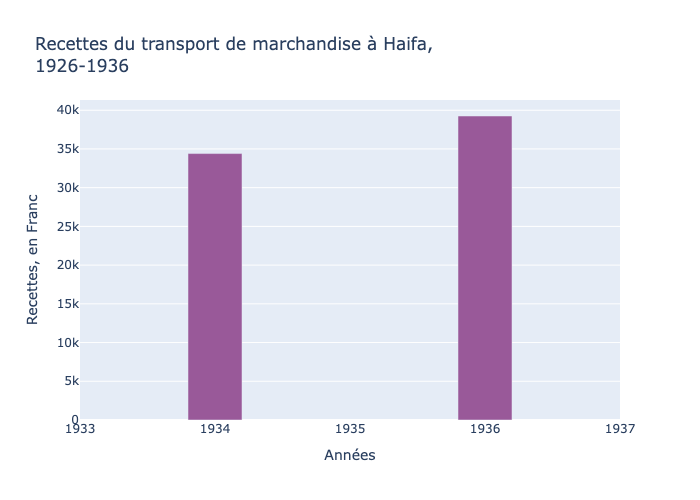

In [17]:
fig = px.bar(
    haifa_departure_year,
    x="year",
    y="income_cargo",
    title=f"Recettes du transport de marchandise à Haifa,<br>{begin_year}-{end_year}",
    labels={
        "year": "Années",
        "income_cargo": "Recettes, en Franc",
    },
)
fig.update_traces(width=0.4, marker_color=COLORS['Haifa']['cargo']['money'])
fig.write_image("haifa-cargo-income.png")
display(Image(filename="haifa-cargo-income.png"))

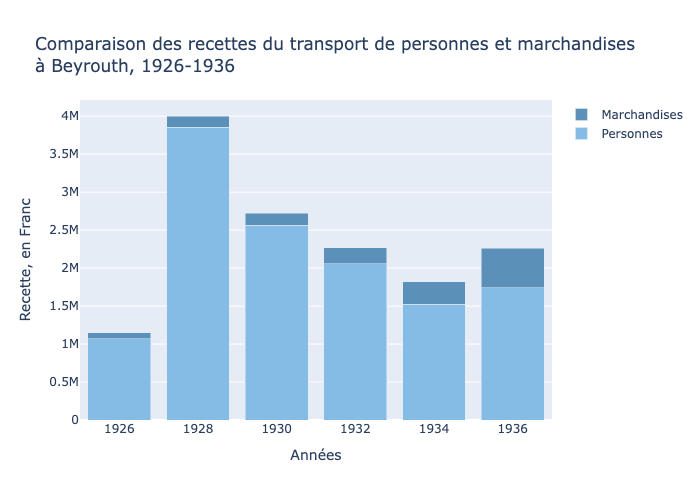

In [18]:
fig = go.Figure()
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["income_passenger"], name="Personnes", marker_color=COLORS['Beyrouth']['persons']['money']))
fig.add_trace(go.Bar(x=beirut_departure_year["year"], y=beirut_departure_year["income_cargo"], name="Marchandises", marker_color=COLORS['Beyrouth']['cargo']['money']))
fig.update_layout(title=f"Comparaison des recettes du transport de personnes et marchandises<br>à Beyrouth, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Recette, en Franc", barmode="stack")
fig.write_image("beirut-person-cargo.png")
display(Image(filename="beirut-person-cargo.png"))

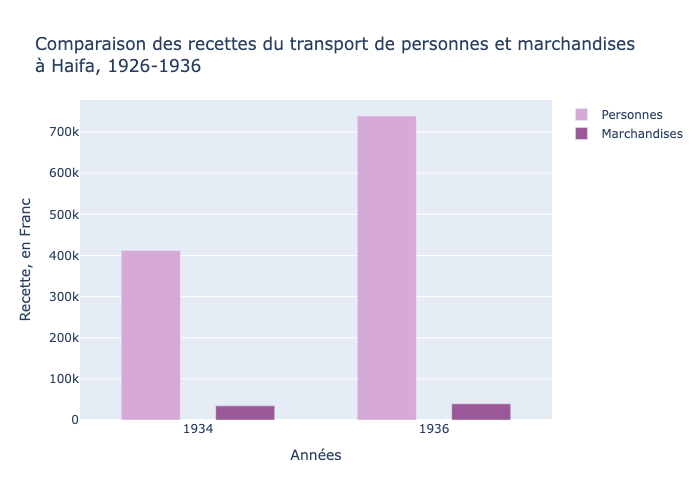

In [19]:
fig = go.Figure()
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["income_passenger"], name="Personnes", marker_color=COLORS['Haifa']['persons']['money'], width=0.5))
fig.add_trace(go.Bar(x=haifa_departure_year["year"], y=haifa_departure_year["income_cargo"], name="Marchandises", marker_color=COLORS['Haifa']['cargo']['money'], width=0.5))
fig.update_layout(title=f"Comparaison des recettes du transport de personnes et marchandises<br>à Haifa, {begin_year}-{end_year}", xaxis_title="Années", yaxis_title="Recette, en Franc")
fig.write_image("haifa-person-cargo.png")
display(Image(filename="haifa-person-cargo.png"))

## D. Etude saisonnière

In [20]:
# Group everything by the month, and make the sum of columns
beirut_arrivals_months_all, beirut_departure_months_all = get_group_by_months(beirut_arrivals, beirut_departures)
beirut_arrivals_months_after_1933, beirut_departure_months_after_1933 = get_group_by_months(beirut_arrivals[beirut_arrivals['year'].isin([1934, 1936])], beirut_departures[beirut_departures['year'].isin([1934, 1936])])
beirut_arrivals_months_before_1933, beirut_departure_months_before_1933 = get_group_by_months(beirut_arrivals[beirut_arrivals['year'].isin([1930, 1932])], beirut_departures[beirut_departures['year'].isin([1930, 1932])])
haifa_arrivals_months_all, haifa_departure_months_all = get_group_by_months(haifa_arrivals, haifa_departures)

months = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]

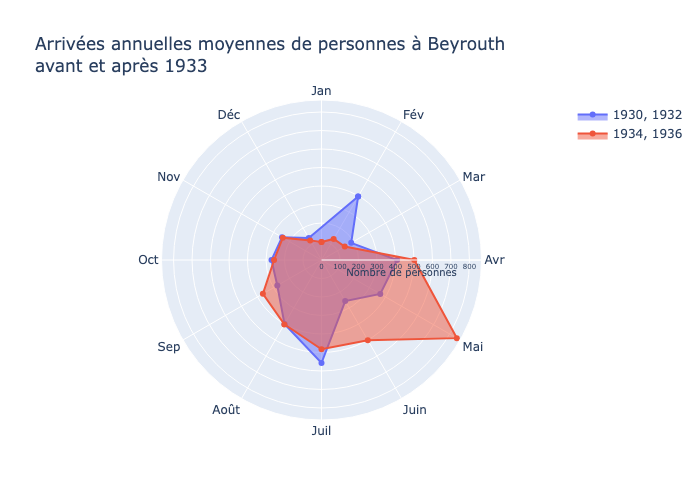

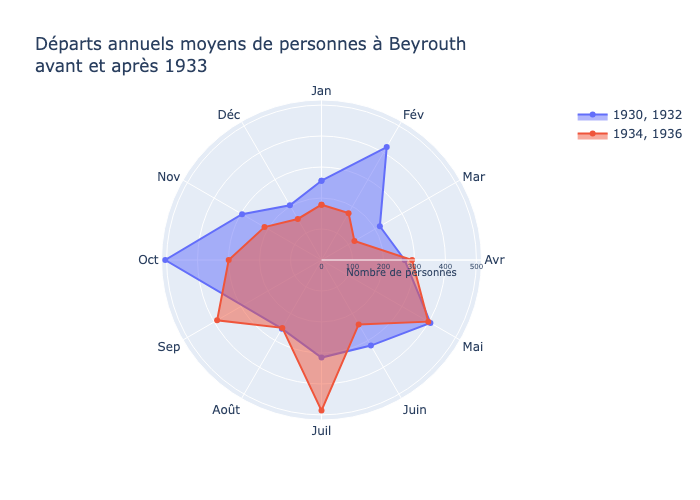

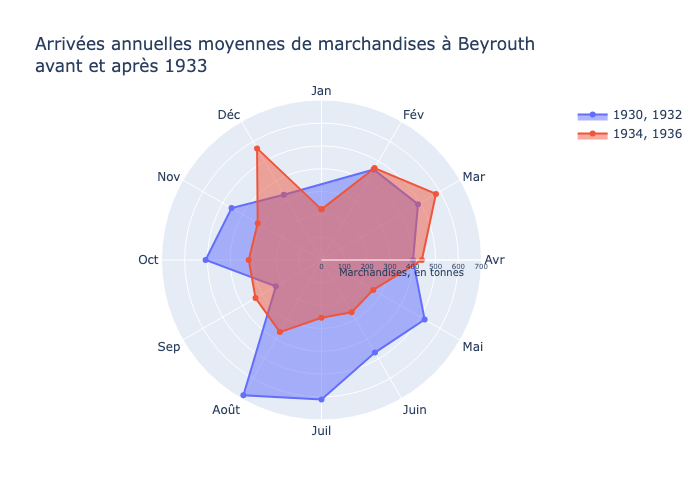

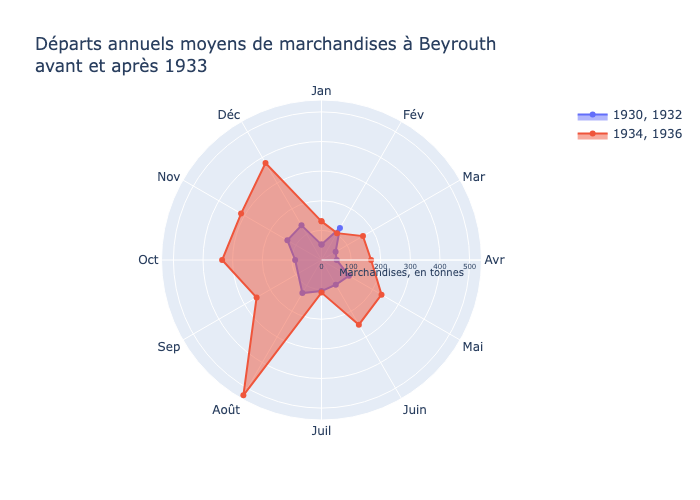

In [21]:
datasets = [
    (beirut_arrivals_months_before_1933, beirut_arrivals_months_after_1933, "total_persons", "Arrivées annuelles moyennes de personnes à Beyrouth<br>avant et après 1933", "Nombre de personnes", "beirut-persons-arrivals-annual-avg.png"),
    (beirut_departure_months_before_1933, beirut_departure_months_after_1933, "total_persons", "Départs annuels moyens de personnes à Beyrouth<br>avant et après 1933", "Nombre de personnes", "beirut-persons-departures-annual-avg.png"),
    (beirut_arrivals_months_before_1933, beirut_arrivals_months_after_1933, "dis_weight_in_tons", "Arrivées annuelles moyennes de marchandises à Beyrouth<br>avant et après 1933", "Marchandises, en tonnes", "beirut-cargo-arrivals-annual-avg.png"),
    (beirut_departure_months_before_1933, beirut_departure_months_after_1933, "emb_weight_in_tons", "Départs annuels moyens de marchandises à Beyrouth<br>avant et après 1933", "Marchandises, en tonnes", "beirut-cargo-departures-annual-avg.png"),
]

for before, after, column, title, ylabel, filename in datasets:
    fig = go.Figure()

    for df, name in [(before, "1930, 1932"), (after, "1934, 1936")]:

        # Convert numeric months to categorical labels
        month_labels = df["month"].map(lambda m: months[int(m) - 1] if isinstance(m, int) else pd.NA)

        # Sort chronologically to ensure the polygon follows the months
        ordered = (df.assign(month_label=month_labels).sort_values("month"))

        r = ordered[column].tolist()
        theta = month_labels.tolist()

        # Close the radar chart
        r.append(r[0])
        theta.append(theta[0])

        fig.add_trace(go.Scatterpolar(r=r, theta=theta, name=name, mode="lines+markers", fill="toself"))

    fig.update_layout(title=title, polar=dict(angularaxis=dict(categoryorder="array", categoryarray=months, rotation=90, direction="clockwise"), radialaxis=dict(title=dict(text=ylabel, font=dict(size=10)), visible=True, tickfont=dict(size=7))))

    fig.write_image(filename)
    display(Image(filename=filename))

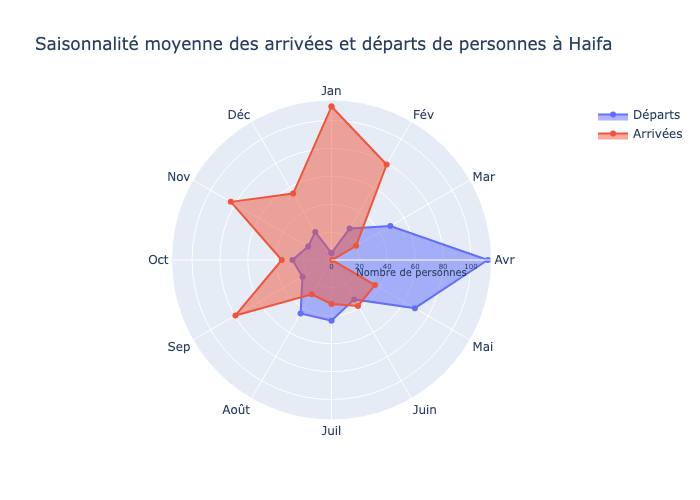

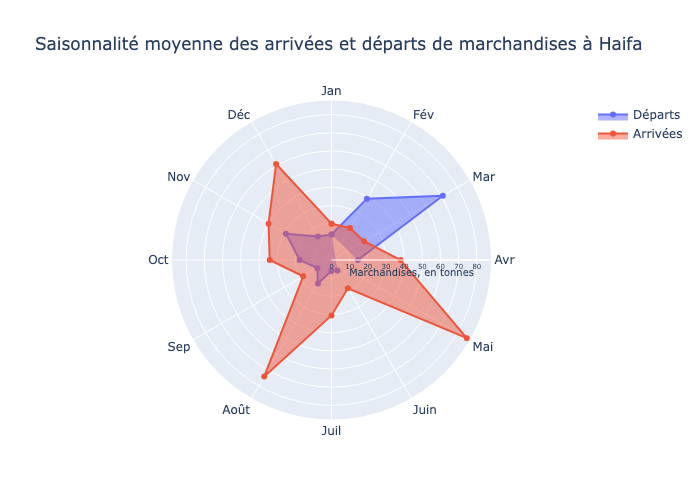

In [22]:
haifa_arrivals_months_all.rename(columns={'dis_weight_in_tons': 'weight_in_tons'}, inplace=True)
haifa_departure_months_all.rename(columns={'emb_weight_in_tons': 'weight_in_tons'}, inplace=True)

datasets = [
    (haifa_arrivals_months_all, haifa_departure_months_all, 'total_persons', 'Saisonnalité moyenne des arrivées et départs de personnes à Haifa', 'Nombre de personnes', 'haifa-persons-annual-avg.png'),
    (haifa_arrivals_months_all, haifa_departure_months_all, 'weight_in_tons', 'Saisonnalité moyenne des arrivées et départs de marchandises à Haifa', 'Marchandises, en tonnes', 'haifa-cargo-annual-avg.png'),
]


fig = go.Figure()

for arrival, departure, column, title, ylabel, filename in datasets:
    fig = go.Figure()

    for df, name in [(departure, "Départs"), (arrival, "Arrivées")]:
        # Convert numeric months to categorical labels
        month_labels = df["month"].map(lambda m: months[int(m) - 1] if isinstance(m, int) else pd.NA)

        # Sort chronologically to ensure the polygon follows the months
        ordered = (df.assign(month_label=month_labels).sort_values("month"))

        r = ordered[column].tolist()
        theta = month_labels.tolist()

        # Close the radar chart
        r.append(r[0])
        theta.append(theta[0])

        fig.add_trace(go.Scatterpolar(r=r, theta=theta, name=name, mode="lines+markers", fill="toself"))

    fig.update_layout(title=title, polar=dict(angularaxis=dict(categoryorder="array", categoryarray=months, rotation=90, direction="clockwise"), radialaxis=dict(title=dict(text=ylabel, font=dict(size=10)), visible=True, tickfont=dict(size=7))))

    fig.write_image(filename)
    display(Image(filename=filename))

In [23]:
beirut_arrivals_months_all['d_1_rate'] = 100 * beirut_arrivals_months_all['d_1'] / 188
beirut_arrivals_months_all['d_2_rate'] = 100 * beirut_arrivals_months_all['d_2'] / 135
beirut_arrivals_months_all['d_3_rate'] = 100 * beirut_arrivals_months_all['d_3'] / 128
beirut_arrivals_months_all['d_4_rate'] = 100 * beirut_arrivals_months_all['d_4'] / 500
beirut_departure_months_all['e_1_rate'] = 100 * beirut_departure_months_all['e_1'] / 188
beirut_departure_months_all['e_2_rate'] = 100 * beirut_departure_months_all['e_2'] / 135
beirut_departure_months_all['e_3_rate'] = 100 * beirut_departure_months_all['e_3'] / 128
beirut_departure_months_all['e_4_rate'] = 100 * beirut_departure_months_all['e_4'] / 500

haifa_arrivals_months_all['d_1_rate'] = 100 * haifa_arrivals_months_all['d_1'] / 188
haifa_arrivals_months_all['d_2_rate'] = 100 * haifa_arrivals_months_all['d_2'] / 135
haifa_arrivals_months_all['d_3_rate'] = 100 * haifa_arrivals_months_all['d_3'] / 128
haifa_arrivals_months_all['d_4_rate'] = 100 * haifa_arrivals_months_all['d_4'] / 500
haifa_departure_months_all['e_1_rate'] = 100 * haifa_departure_months_all['e_1'] / 188
haifa_departure_months_all['e_2_rate'] = 100 * haifa_departure_months_all['e_2'] / 135
haifa_departure_months_all['e_3_rate'] = 100 * haifa_departure_months_all['e_3'] / 128
haifa_departure_months_all['e_4_rate'] = 100 * haifa_departure_months_all['e_4'] / 500

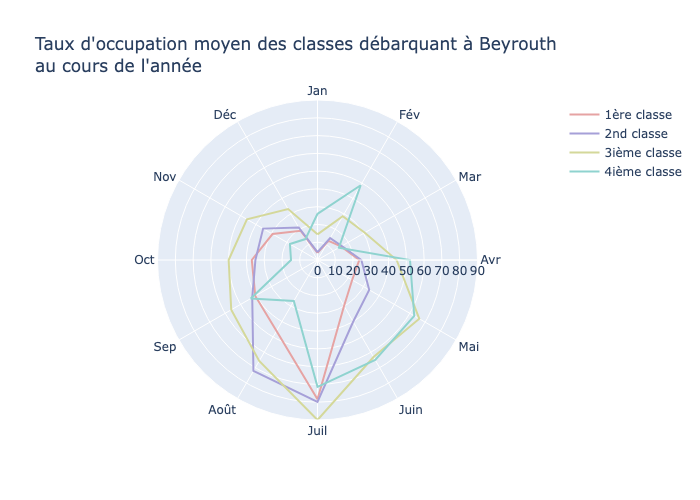

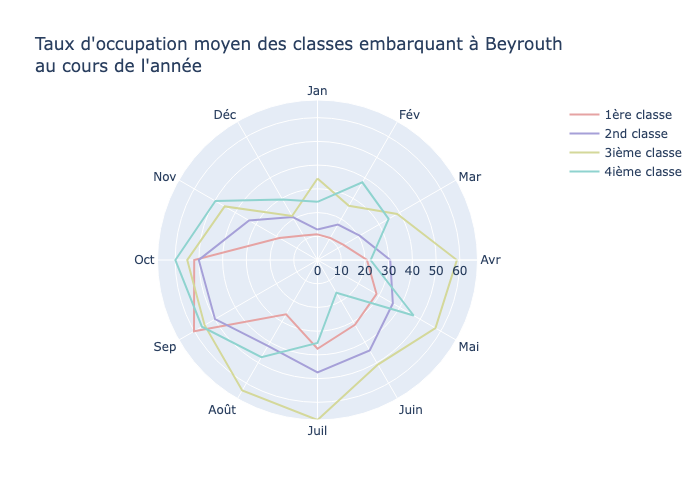

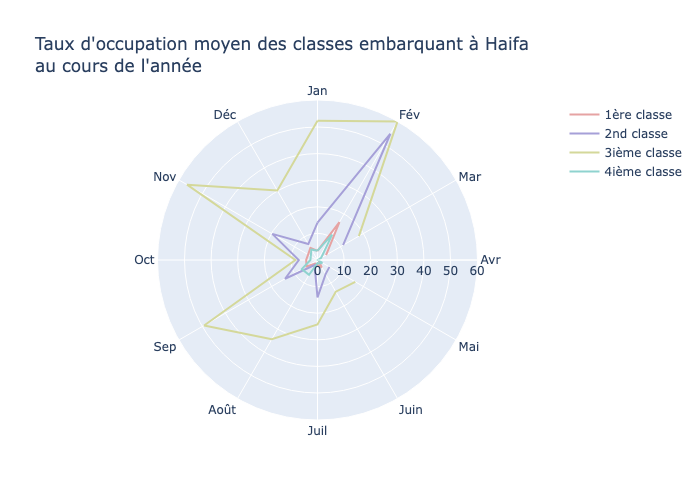

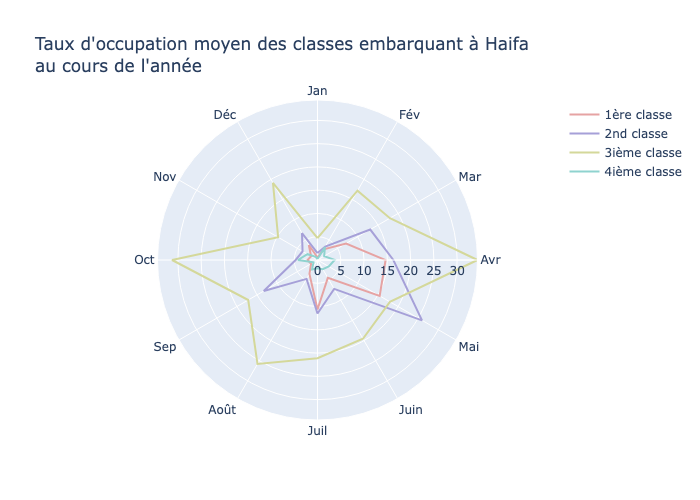

In [24]:
def add_radar_traces(fig, df, columns):
    df = df.sort_values("month")
    months_labels = [months[int(m) - 1] for m in df["month"]]
    theta = months_labels + [months_labels[0]]

    for i, (column, name, color) in enumerate(columns):
        values = df[column].tolist()
        fig.add_trace(go.Scatterpolar(theta=theta, r=values + [values[0]], name=name, fill="none", mode="lines", marker_color=color))

    fig.update_layout(polar=dict(angularaxis=dict(categoryorder="array", categoryarray=months_labels, direction="clockwise")))


fig = go.Figure()
add_radar_traces(fig, beirut_arrivals_months_all, [
    ("d_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("d_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("d_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("d_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title="Taux d'occupation moyen des classes débarquant à Beyrouth<br>au cours de l'année")
fig.write_image("beirut-persons-arrivals-annual-avg-classes.png")
display(Image(filename="beirut-persons-arrivals-annual-avg-classes.png"))

fig = go.Figure()
add_radar_traces(fig, beirut_departure_months_all, [
    ("e_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("e_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("e_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("e_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title="Taux d'occupation moyen des classes embarquant à Beyrouth<br>au cours de l'année")
fig.write_image("beirut-persons-departures-annual-avg-classes.png")
display(Image(filename="beirut-persons-departures-annual-avg-classes.png"))


fig = go.Figure()
add_radar_traces(fig, haifa_arrivals_months_all, [
    ("d_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("d_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("d_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("d_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title="Taux d'occupation moyen des classes embarquant à Haifa<br>au cours de l'année")
fig.write_image("haifa-persons-departures-annual-avg-classes.png")
display(Image(filename="haifa-persons-departures-annual-avg-classes.png"))

fig = go.Figure()
add_radar_traces(fig, haifa_departure_months_all, [
    ("e_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("e_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("e_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("e_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title="Taux d'occupation moyen des classes embarquant à Haifa<br>au cours de l'année")
fig.write_image("haifa-persons-departures-annual-avg-classes.png")
display(Image(filename="haifa-persons-departures-annual-avg-classes.png"))

In [25]:
beirut_arrivals_year['d_1_rate'] = 100 * beirut_arrivals_year['d_1'] / 188
beirut_arrivals_year['d_2_rate'] = 100 * beirut_arrivals_year['d_2'] / 135
beirut_arrivals_year['d_3_rate'] = 100 * beirut_arrivals_year['d_3'] / 128
beirut_arrivals_year['d_4_rate'] = 100 * beirut_arrivals_year['d_4'] / 500
beirut_departure_year['e_1_rate'] = 100 * beirut_departure_year['e_1'] / 188
beirut_departure_year['e_2_rate'] = 100 * beirut_departure_year['e_2'] / 135
beirut_departure_year['e_3_rate'] = 100 * beirut_departure_year['e_3'] / 128
beirut_departure_year['e_4_rate'] = 100 * beirut_departure_year['e_4'] / 500

haifa_arrivals_year['d_1_rate'] = 100 * haifa_arrivals_year['d_1'] / 188
haifa_arrivals_year['d_2_rate'] = 100 * haifa_arrivals_year['d_2'] / 135
haifa_arrivals_year['d_3_rate'] = 100 * haifa_arrivals_year['d_3'] / 128
haifa_arrivals_year['d_4_rate'] = 100 * haifa_arrivals_year['d_4'] / 500
haifa_departure_year['e_1_rate'] = 100 * haifa_departure_year['e_1'] / 188
haifa_departure_year['e_2_rate'] = 100 * haifa_departure_year['e_2'] / 135
haifa_departure_year['e_3_rate'] = 100 * haifa_departure_year['e_3'] / 128
haifa_departure_year['e_4_rate'] = 100 * haifa_departure_year['e_4'] / 500

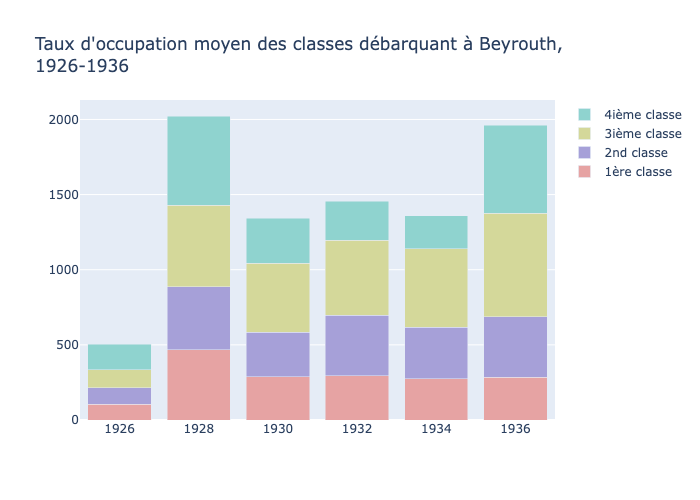

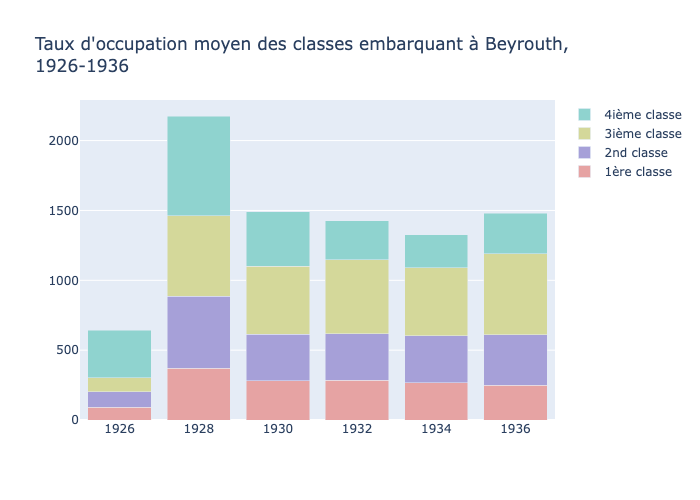

In [26]:
def add_line_traces(fig, df, columns):
    for col, name, color in columns:
        fig.add_trace(go.Bar(x=df["year"], y=df[col], name=name, marker_color=color))


fig = go.Figure()
add_line_traces(fig, beirut_arrivals_year, [
    ("d_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("d_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("d_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("d_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title=f"Taux d'occupation moyen des classes débarquant à Beyrouth,<br>{begin_year}-{end_year}", barmode="stack")
fig.write_image("beirut-persons-arrivals-year-avg-classes.png")
display(Image(filename="beirut-persons-arrivals-year-avg-classes.png"))

fig = go.Figure()
add_line_traces(fig, beirut_departure_year, [
    ("e_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("e_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("e_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("e_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title=f"Taux d'occupation moyen des classes embarquant à Beyrouth,<br>{begin_year}-{end_year}", barmode="stack")
fig.write_image("beirut-persons-departures-year-avg-classes.png")
display(Image(filename="beirut-persons-departures-year-avg-classes.png"))


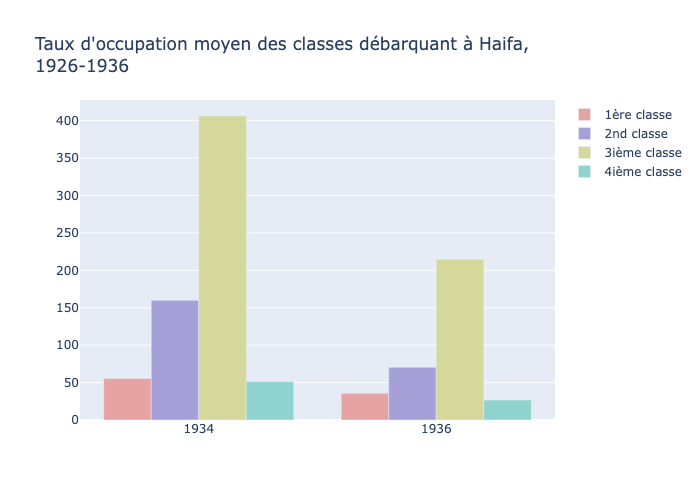

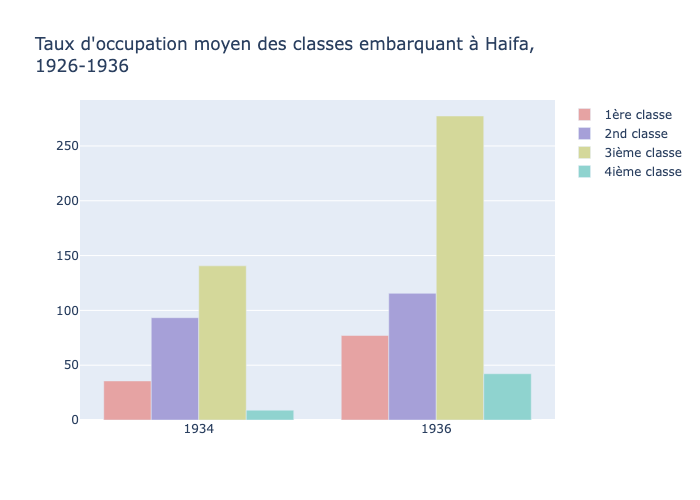

In [27]:
def add_line_traces(fig, df, columns):
    for col, name, color in columns:
        fig.add_trace(go.Bar(x=df["year"], y=df[col], name=name, marker_color=color))

fig = go.Figure()
add_line_traces(fig, haifa_arrivals_year, [
    ("d_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("d_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("d_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("d_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title=f"Taux d'occupation moyen des classes débarquant à Haifa,<br>{begin_year}-{end_year}")
fig.write_image("haifa-persons-arrivals-year-avg-classes.png")
display(Image(filename="haifa-persons-arrivals-year-avg-classes.png"))

fig = go.Figure()
add_line_traces(fig, haifa_departure_year, [
    ("e_1_rate", "1ère classe", COLORS_CLASSES[0]),
    ("e_2_rate", "2nd classe", COLORS_CLASSES[1]),
    ("e_3_rate", "3ième classe", COLORS_CLASSES[2]),
    ("e_4_rate", "4ième classe", COLORS_CLASSES[3]),
])
fig.update_layout(title=f"Taux d'occupation moyen des classes embarquant à Haifa,<br>{begin_year}-{end_year}")
fig.write_image("haifa-persons-departures-year-avg-classes.png")
display(Image(filename="haifa-persons-departures-year-avg-classes.png"))

___

# Autres graphiques

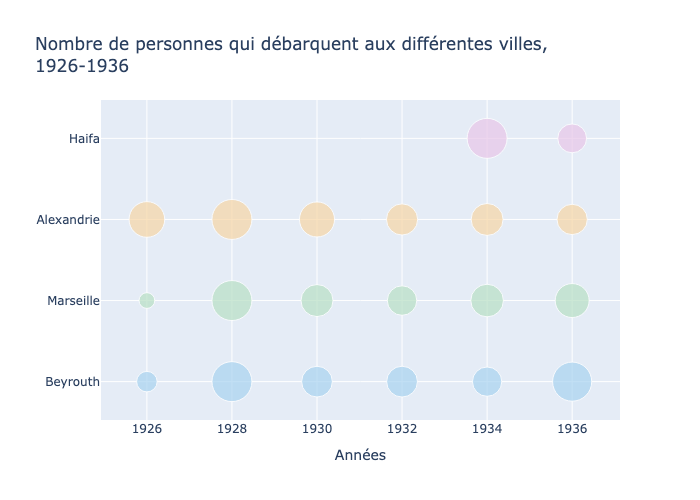

In [28]:
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=beirut_arrivals_year["year"],
    y=[1] * len(beirut_arrivals_year),
    mode="markers",
    marker=dict(size=beirut_arrivals_year["total_persons"], sizemode="area", sizeref=2. * beirut_arrivals_year["total_persons"].max() / (40. ** 2), sizemin=4),
    name="Beyrouth",
    text=beirut_arrivals_year["total_persons"],
    marker_color=COLORS['Beyrouth']['persons']['arrivals']
))

fig.add_trace(go.Scatter(
    x=marseille_arrivals_year["year"],
    y=[2] * len(marseille_arrivals_year),
    mode="markers",
    marker=dict(size=marseille_arrivals_year["total_persons"], sizemode="area", sizeref=2. * marseille_arrivals_year["total_persons"].max() / (40. ** 2), sizemin=4),
    name="Marseille",
    text=marseille_arrivals_year["total_persons"],
    marker_color=COLORS['Marseille']['persons']['arrivals']
))

fig.add_trace(go.Scatter(
    x=alexandria_arrivals_year["year"],
    y=[3] * len(alexandria_arrivals_year),
    mode="markers",
    marker=dict(size=alexandria_arrivals_year["total_persons"], sizemode="area", sizeref=2. * alexandria_arrivals_year["total_persons"].max() / (40. ** 2), sizemin=4),
    name="Alexandrie",
    text=alexandria_arrivals_year["total_persons"],
    marker_color=COLORS['Alexandrie']['persons']['arrivals']
))

fig.add_trace(go.Scatter(
    x=haifa_arrivals_year["year"],
    y=[4] * len(haifa_arrivals_year),
    mode="markers",
    marker=dict(size=haifa_arrivals_year["total_persons"], sizemode="area", sizeref=2. * haifa_arrivals_year["total_persons"].max() / (40. ** 2), sizemin=4),
    name="Haifa",
    text=haifa_arrivals_year["total_persons"],
    marker_color=COLORS['Haifa']['persons']['arrivals']
))

fig.update_layout(
    title=f"Nombre de personnes qui débarquent aux différentes villes,<br>{begin_year}-{end_year}",
    xaxis_title="Années",
    yaxis=dict(
        tickmode="array",
        tickvals=[1, 2, 3, 4],
        ticktext=["Beyrouth", "Marseille", "Alexandrie", "Haifa"],
        title=""
    ),
    showlegend=False
)

fig.write_image("persons-arrivals-city-bubble.png")
display(Image(filename="persons-arrivals-city-bubble.png"))

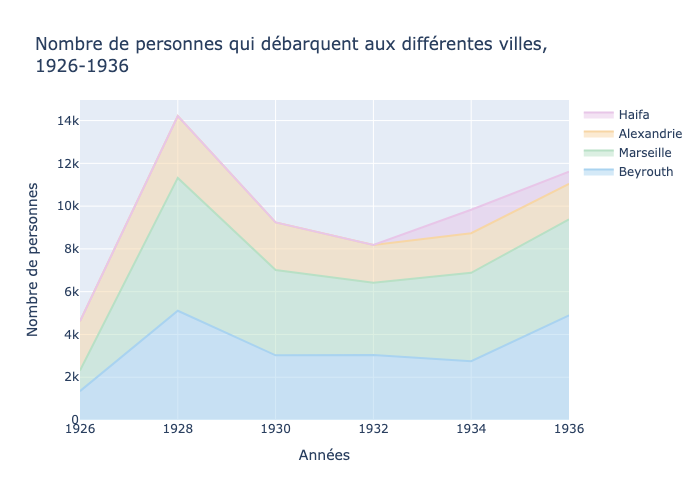

In [29]:
fig = go.Figure()

for df, name, color in [
    (beirut_arrivals_year, "Beyrouth", COLORS['Beyrouth']['persons']['arrivals']),
    (marseille_arrivals_year, "Marseille", COLORS['Marseille']['persons']['arrivals']),
    (alexandria_arrivals_year, "Alexandrie", COLORS['Alexandrie']['persons']['arrivals']),
    (haifa_arrivals_year, "Haifa", COLORS['Haifa']['persons']['arrivals']),
]:
    fig.add_trace(go.Scatter(
        x=df["year"],
        y=df["total_persons"],
        mode="lines",
        stackgroup="one",
        name=name,
        marker_color=color
    ))

fig.update_layout(
    title=f"Nombre de personnes qui débarquent aux différentes villes,<br>{begin_year}-{end_year}",
    xaxis_title="Années",
    yaxis_title="Nombre de personnes",
    showlegend=True,
)

fig.write_image("persons-arrivals-city-stackedarea.png")
display(Image(filename="persons-arrivals-city-stackedarea.png"))

___

# Problèmes rencontrés :

## La somme des embarqués est différente de la somme des débarqués

In [30]:
table = pd.read_sql_query("""
    SELECT sp.d_1, sp.d_2, sp.d_3, sp.d_4, sp.e_1, sp.e_2, sp.e_3, sp.e_4, s.fk_voyage
    FROM borders.step_persons sp
    inner join borders.step s on s.pk_step = sp.fk_step
""", conn)

table1 = table.groupby('fk_voyage').sum().reset_index()
table1 = table1[table1['d_1'] != table1['e_1']][['fk_voyage', 'd_1', 'e_1']].reset_index(drop=True)
for col in table1.columns:
    if col == "fk_voyage": continue
    table1[col] = table1[col].astype(pd.Int64Dtype())

display(table1)

table2 = table.groupby('fk_voyage').sum().reset_index()
table2 = table2[table2['d_2'] != table2['e_2']][['fk_voyage', 'd_2', 'e_2']].reset_index(drop=True)
for col in table2.columns:
    if col == "fk_voyage": continue
    table2[col] = table2[col].astype(pd.Int64Dtype())

display(table2)

table3 = table.groupby('fk_voyage').sum().reset_index()
table3 = table3[table3['d_3'] != table3['e_3']][['fk_voyage', 'd_3', 'e_3']].reset_index(drop=True)
for col in table3.columns:
    if col == "fk_voyage": continue
    table3[col] = table3[col].astype(pd.Int64Dtype())

display(table3)

table4 = table.groupby('fk_voyage').sum().reset_index()
table4 = table4[table4['d_4'] != table4['e_4']][['fk_voyage', 'd_4', 'e_4']].reset_index(drop=True)
for col in table4.columns:
    if col == "fk_voyage": continue
    table4[col] = table4[col].astype(pd.Int64Dtype())

display(table4)

,fk_voyage,d_1,e_1
0,3,305,266
1,8,230,323
2,14,60,294
3,21,197,193
4,25,176,177
5,73,224,219


,fk_voyage,d_2,e_2
0,3,241,236
1,7,198,199
2,8,171,283
3,14,67,237
4,39,156,219
5,76,128,108
6,82,221,231


,fk_voyage,d_3,e_3
0,3,182,170
1,8,173,242
2,9,385,275
3,14,100,324
4,35,234,334
5,62,256,206
6,76,143,144


,fk_voyage,d_4,e_4
0,3,332,596
1,8,314,405
2,9,131,342
3,11,164,163
4,14,247,351
5,64,279,276
6,71,1888,961
7,73,760,740


## Plus de personnes ne montent qu'il n'y a de place totale

In [31]:
table = pd.read_sql_query("""
    SELECT sp.d_1, sp.d_2, sp.d_3, sp.d_4, sp.e_1, sp.e_2, sp.e_3, sp.e_4, s.pk_step
    FROM borders.step_persons sp
    inner join borders.step s on s.pk_step = sp.fk_step
    inner join borders.voyage v on v.pk_voyage = s.fk_voyage and v.fk_ship = 1
""", conn)
for col in table.columns:
    table[col] = table[col].astype(pd.Int64Dtype())

print('Le Mariette Pacha ne dispose que de 188 place en première classe, or:')
display(table[['pk_step', 'd_1']][table['d_1'] > 188])
display(table[['pk_step', 'e_1']][table['e_1'] > 188])

print('Le Mariette Pacha ne dispose que de 135 place en seconde classe, or:')
display(table[['pk_step', 'd_2']][table['d_2'] > 135])
display(table[['pk_step', 'e_2']][table['e_2'] > 135])

print('Le Mariette Pacha ne dispose que de 128 place en troisième classe, or:')
display(table[['pk_step', 'd_3']][table['d_3'] > 128])
display(table[['pk_step', 'e_3']][table['e_3'] > 128])

print('Le Mariette Pacha ne dispose que de 500 place en quatrième classe, or:')
display(table[['pk_step', 'd_4']][table['d_4'] > 500])
display(table[['pk_step', 'e_4']][table['e_4'] > 500])

Le Mariette Pacha ne dispose que de 188 place en première classe, or:


,pk_step,d_1
42,47,196
205,246,221
426,474,196


,pk_step,e_1
0,6,215
2,12,204


Le Mariette Pacha ne dispose que de 135 place en seconde classe, or:


,pk_step,d_2
37,41,141
88,108,145
109,123,136
202,243,136
426,474,157


...

,pk_step,d_3
37,41,131
42,47,154
47,52,211
74,80,173
85,104,155
88,108,131
102,98,173
106,121,131
109,123,146
122,137,153


,pk_step,e_3
0,6,139
43,48,139
82,101,173
96,91,137
103,118,206
110,125,133
126,141,187
147,162,144
152,169,136
178,218,183


Le Mariette Pacha ne dispose que de 500 place en quatrième classe, or:


,pk_step,d_4
10,17,785
34,38,630
37,41,678
106,121,760
150,165,1002
217,258,517
222,263,517
285,326,601
287,328,528
417,465,691


,pk_step,e_4
7,8,747
32,36,576
34,38,658
103,118,768
147,162,984
215,256,536
220,261,536
283,324,609
285,326,526
415,463,652
